In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("machine/data.csv", parse_dates=["Date"])
df = df.rename(columns={"Category_y": "Category", "Product_Name_y": "Product"})

df["Gross"] = df["Quantity"] * df["Unit_Price"]
df["Revenue"] = df["Gross"] * (1 - df["Discount"])
df["Cost"] = df["Quantity"] * df["Cost_Price"]
df["Profit"] = df["Revenue"] - df["Cost"]
df["Year"] = df["Date"].dt.year

invoices = df.groupby("Transaction_ID").agg(
    Customer_ID=("Customer_ID", "first"),
    Date=("Date", "first"),
    Channel=("Channel", "first"),
    Revenue=("Revenue", "sum"),
    Profit=("Profit", "sum"),
)
invoices["Year"] = invoices["Date"].dt.year

df.head()

,Transaction_ID,Customer_ID,Date,Product_ID,Quantity,Unit_Price,Discount,Store_Name,Channel,Age_Group,...,City_y,Area,Region,Size_Class,Opening_Date,Gross,Revenue,Cost,Profit,Year
0,T000001,C00112,2024-01-01,P117,1,70.0,0.0,Cairo - New Cairo,In-Store,18-24,...,Cairo,New Cairo,Greater Cairo,Large,2021-02-25,70.0,70.0,52.0,18.0,2024
1,T000001,C00112,2024-01-01,P114,1,30.0,0.0,Cairo - New Cairo,In-Store,18-24,...,Cairo,New Cairo,Greater Cairo,Large,2021-02-25,30.0,30.0,24.0,6.0,2024
2,T000001,C00112,2024-01-01,P125,4,28.0,0.0,Cairo - New Cairo,In-Store,18-24,...,Cairo,New Cairo,Greater Cairo,Large,2021-02-25,112.0,112.0,76.0,36.0,2024
3,T000001,C00112,2024-01-01,P062,3,55.0,0.0,Cairo - New Cairo,In-Store,18-24,...,Cairo,New Cairo,Greater Cairo,Large,2021-02-25,165.0,165.0,126.0,39.0,2024
4,T000001,C00112,2024-01-01,P085,2,24.0,0.0,Cairo - New Cairo,In-Store,18-24,...,Cairo,New Cairo,Greater Cairo,Large,2021-02-25,48.0,48.0,34.0,14.0,2024


## 1. Check the dashboard numbers

In [2]:
revenue = df["Revenue"].sum()
profit = df["Profit"].sum()

print("Total Revenue:", round(revenue / 1e6, 2), "M")
print("Total Profit:", round(profit / 1e6, 2), "M")
print("Profit Margin:", round(profit / revenue * 100, 2), "%")
print("Discount %:", round((df["Gross"].sum() - revenue) / df["Gross"].sum() * 100, 2), "%")
print("Total Invoices:", len(invoices))
print("Avg Invoice Value:", round(invoices["Revenue"].mean(), 2))
print("Total Customers:", df["Customer_ID"].nunique())

Total Revenue: 75.14 M
Total Profit: 20.1 M
Profit Margin: 26.75 %
Discount %: 3.35 %
Total Invoices: 136437
Avg Invoice Value: 550.75
Total Customers: 7000


Revenue       -0.6
Invoices      -9.5
Customers     -9.4
Avg Invoice    9.8
dtype: float64


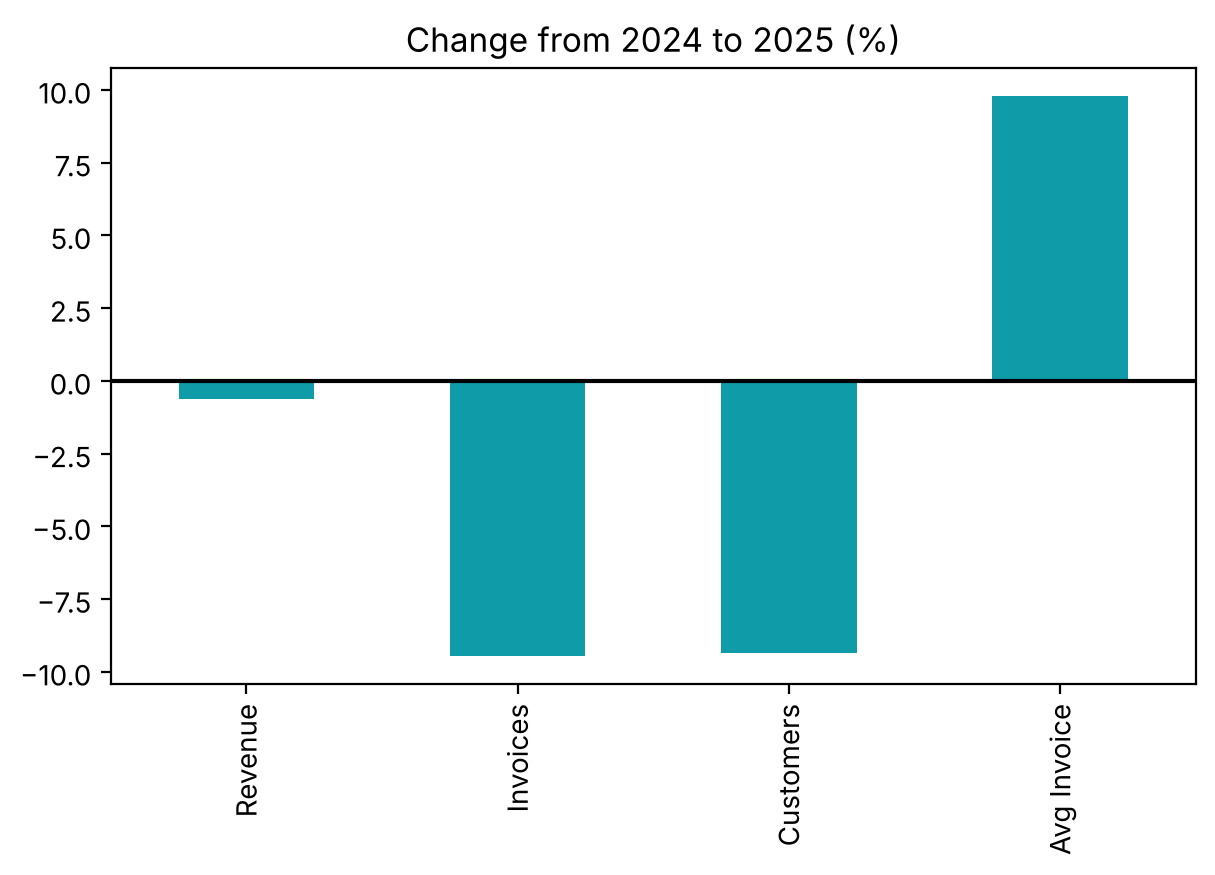

Insight: the real revenue growth is -0.61 %, not 99.39%.
Revenue is flat, but invoices and customers are going down.


In [3]:
yearly = pd.DataFrame({
    "Revenue": df.groupby("Year")["Revenue"].sum(),
    "Invoices": invoices.groupby("Year").size(),
    "Customers": invoices.groupby("Year")["Customer_ID"].nunique(),
})
yearly["Avg Invoice"] = yearly["Revenue"] / yearly["Invoices"]

change = (yearly.loc[2025] / yearly.loc[2024] - 1) * 100
print(change.round(1))

change.plot(kind="bar", color="#0F9BA8", figsize=(7, 4))
plt.axhline(0, color="black")
plt.title("Change from 2024 to 2025 (%)")
plt.show()

print("Insight: the real revenue growth is", round(change["Revenue"], 2), "%, not 99.39%.")
print("Revenue is flat, but invoices and customers are going down.")

In [4]:
store_size = df.groupby("Store_Name")["Size_Class"].first()
invoices["Store_Size"] = df.groupby("Transaction_ID")["Store_Name"].first().map(store_size)

print(invoices.groupby("Store_Size")["Revenue"].mean().round(0))
print("The dashboard shows about 250 here, but the correct value is about 550.")

Store_Size
Large     540.0
Medium    554.0
Small     557.0
Name: Revenue, dtype: float64
The dashboard shows about 250 here, but the correct value is about 550.


## 2. Ramadan and weekdays

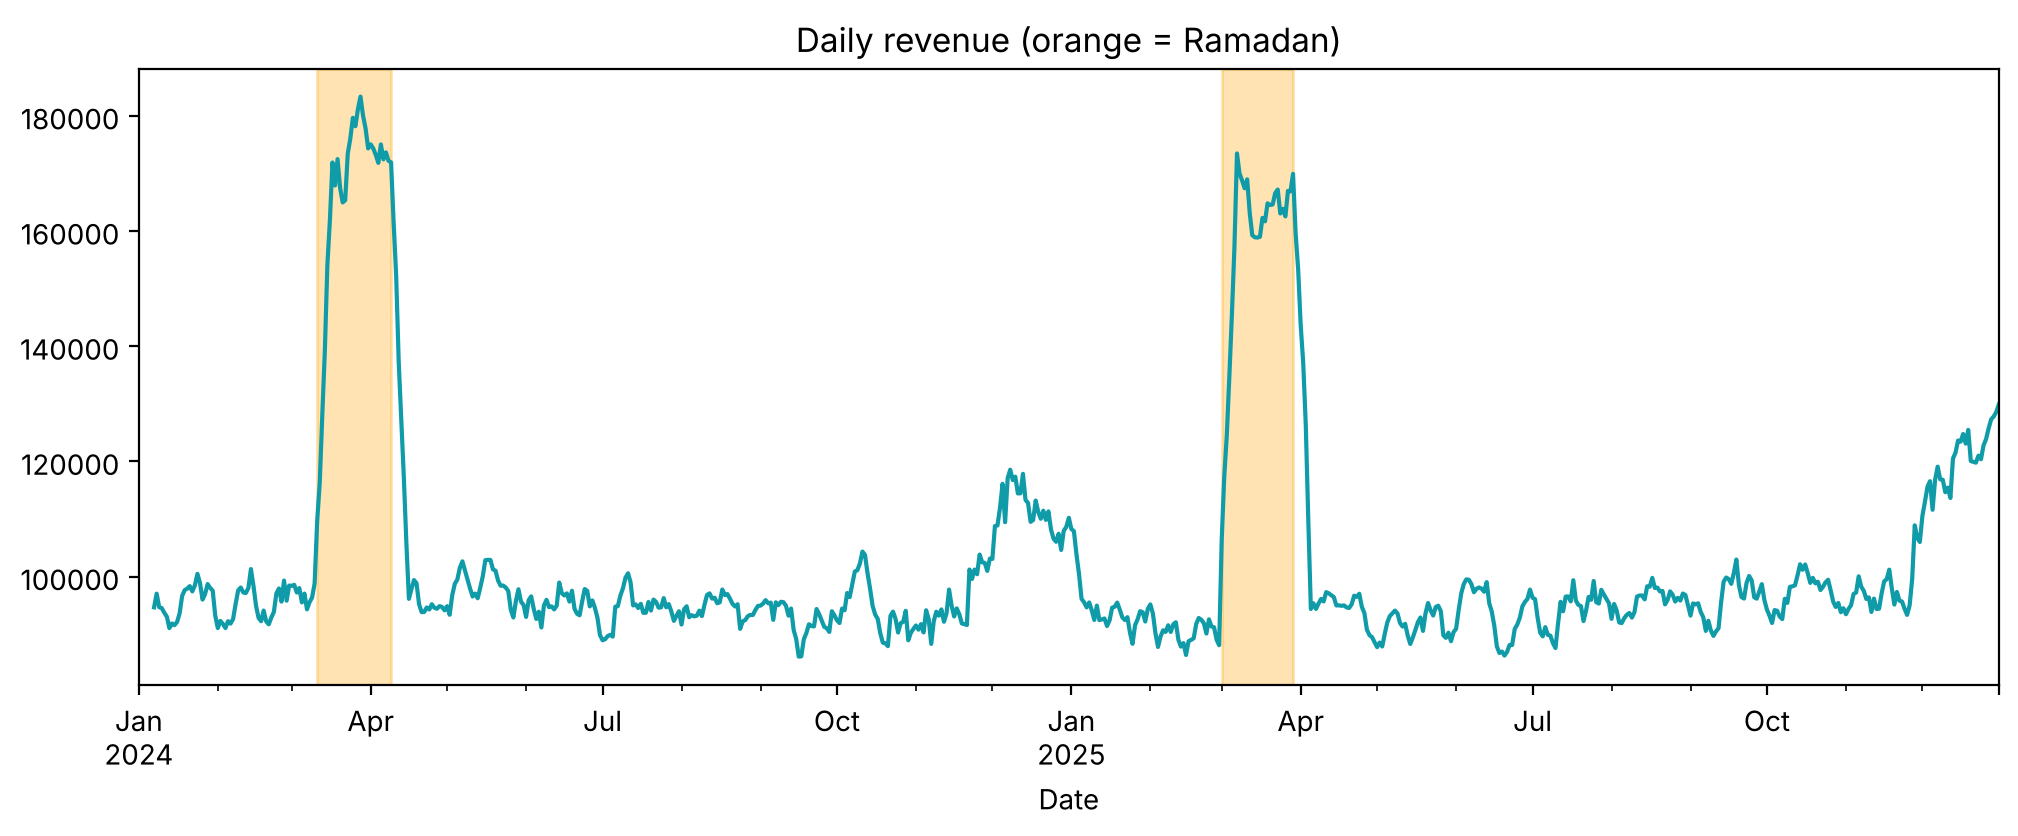

Insight: daily revenue in Ramadan is 1.76 times the rest of the year.


In [5]:
daily = df.groupby("Date")["Revenue"].sum()

plt.figure(figsize=(12, 4))
daily.rolling(7).mean().plot(color="#0F9BA8")
plt.axvspan("2024-03-11", "2024-04-09", color="orange", alpha=0.3)
plt.axvspan("2025-03-01", "2025-03-29", color="orange", alpha=0.3)
plt.title("Daily revenue (orange = Ramadan)")
plt.show()

is_ramadan = (
    ((daily.index >= "2024-03-11") & (daily.index <= "2024-04-09"))
    | ((daily.index >= "2025-03-01") & (daily.index <= "2025-03-29"))
)
ratio = daily[is_ramadan].mean() / daily[~is_ramadan].mean()
print("Insight: daily revenue in Ramadan is", round(ratio, 2), "times the rest of the year.")

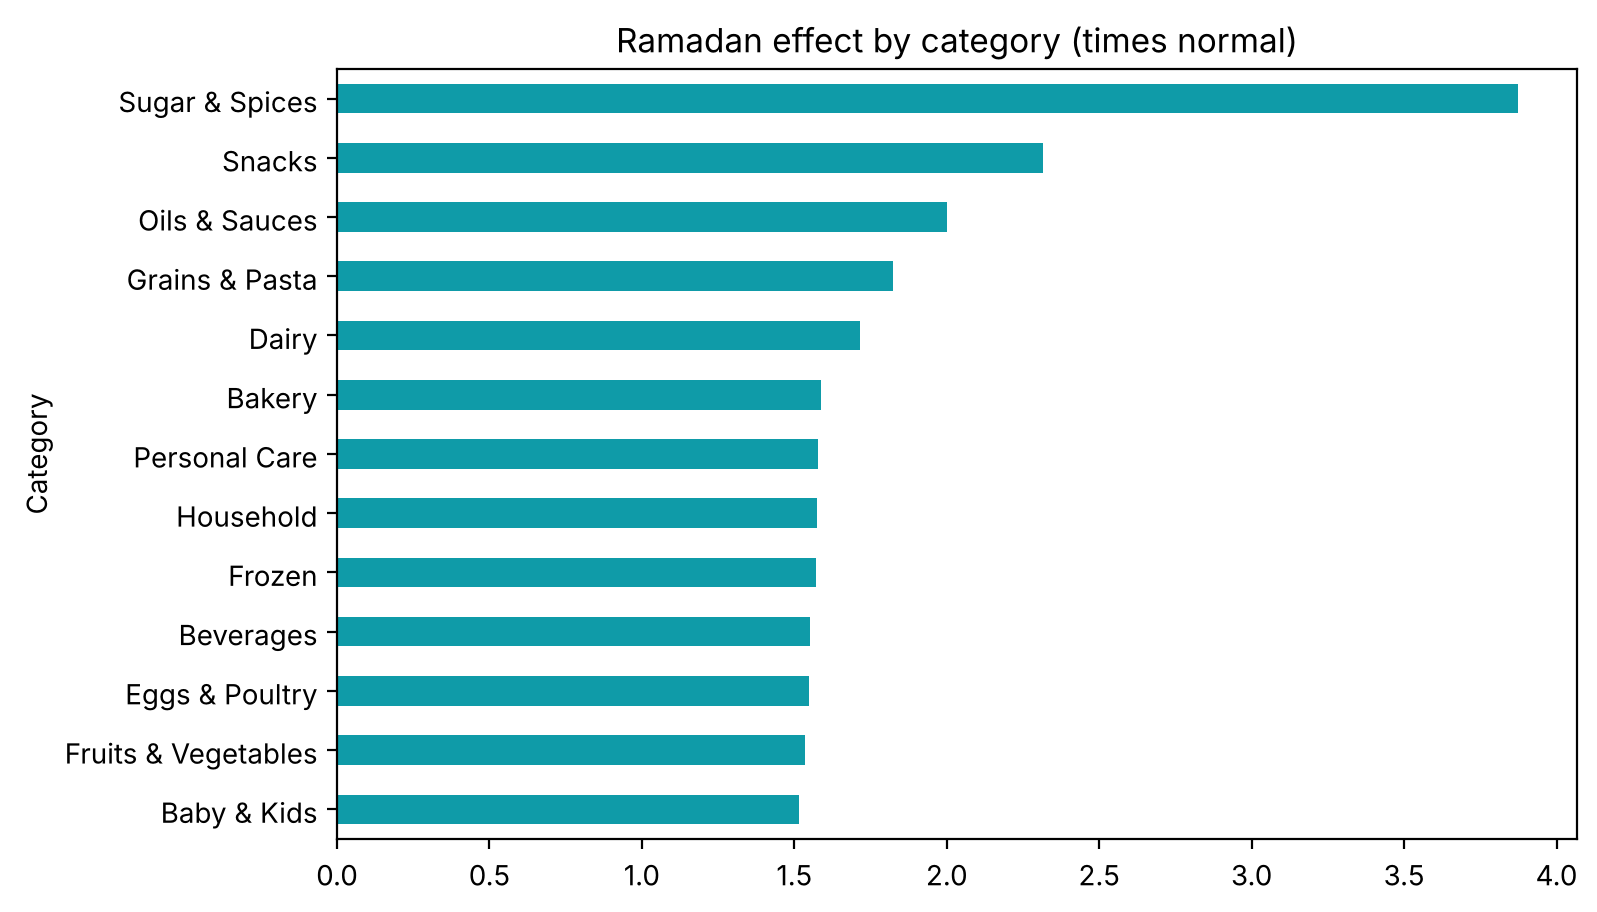

In [6]:
by_category = df.groupby(["Date", "Category"])["Revenue"].sum().unstack(fill_value=0)
in_ramadan = by_category.index.isin(daily.index[is_ramadan])

lift = by_category[in_ramadan].mean() / by_category[~in_ramadan].mean()
lift.sort_values().plot(kind="barh", color="#0F9BA8", figsize=(8, 5))
plt.title("Ramadan effect by category (times normal)")
plt.show()

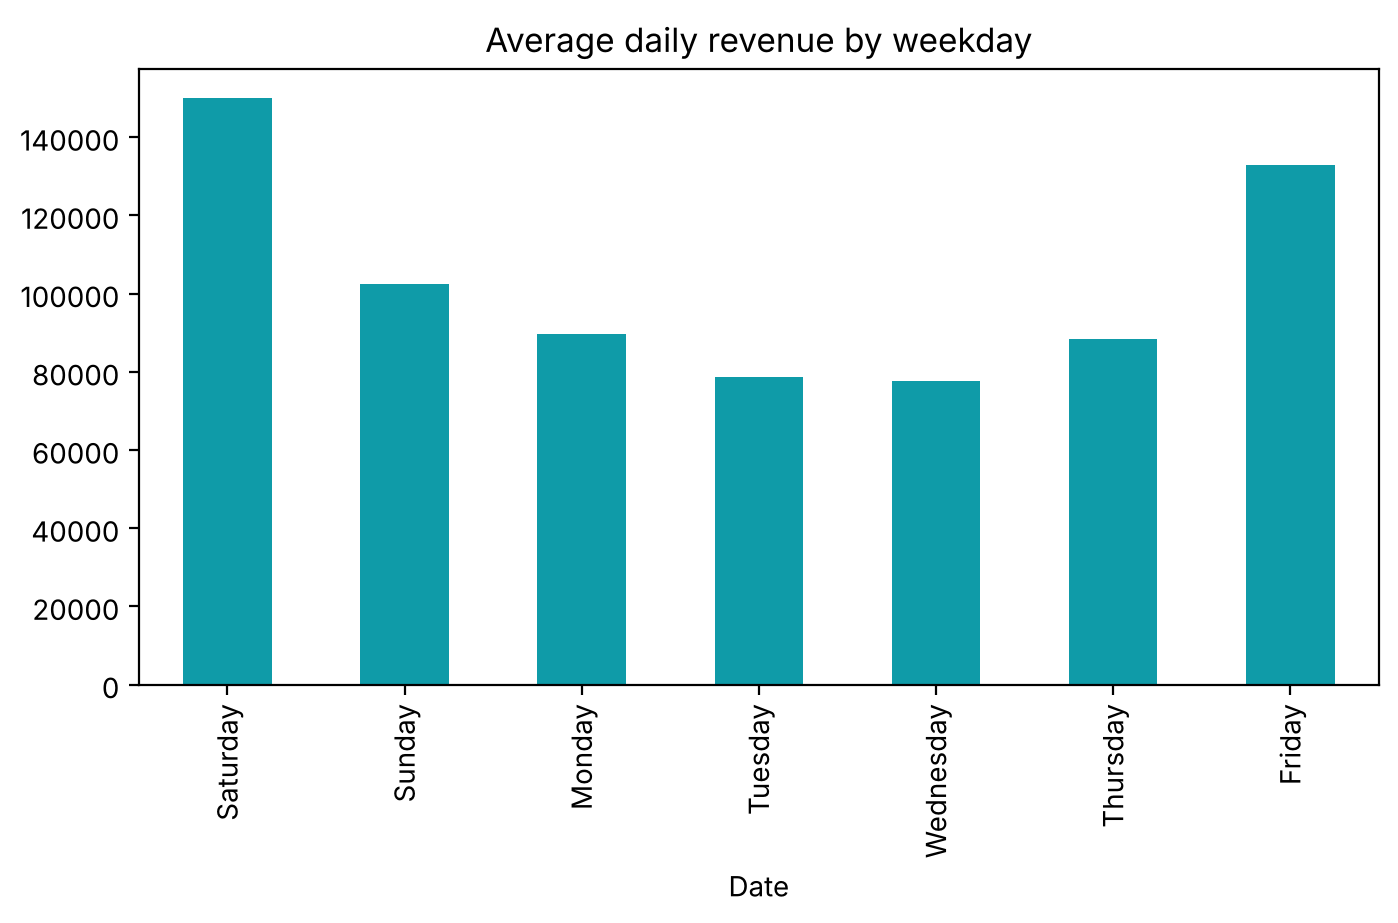

Insight: Friday and Saturday are the busiest days.


In [7]:
order = ["Saturday", "Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
weekday = daily.groupby(daily.index.day_name()).mean().reindex(order)

weekday.plot(kind="bar", color="#0F9BA8", figsize=(8, 4))
plt.title("Average daily revenue by weekday")
plt.show()

print("Insight: Friday and Saturday are the busiest days.")

## 3. Discounts

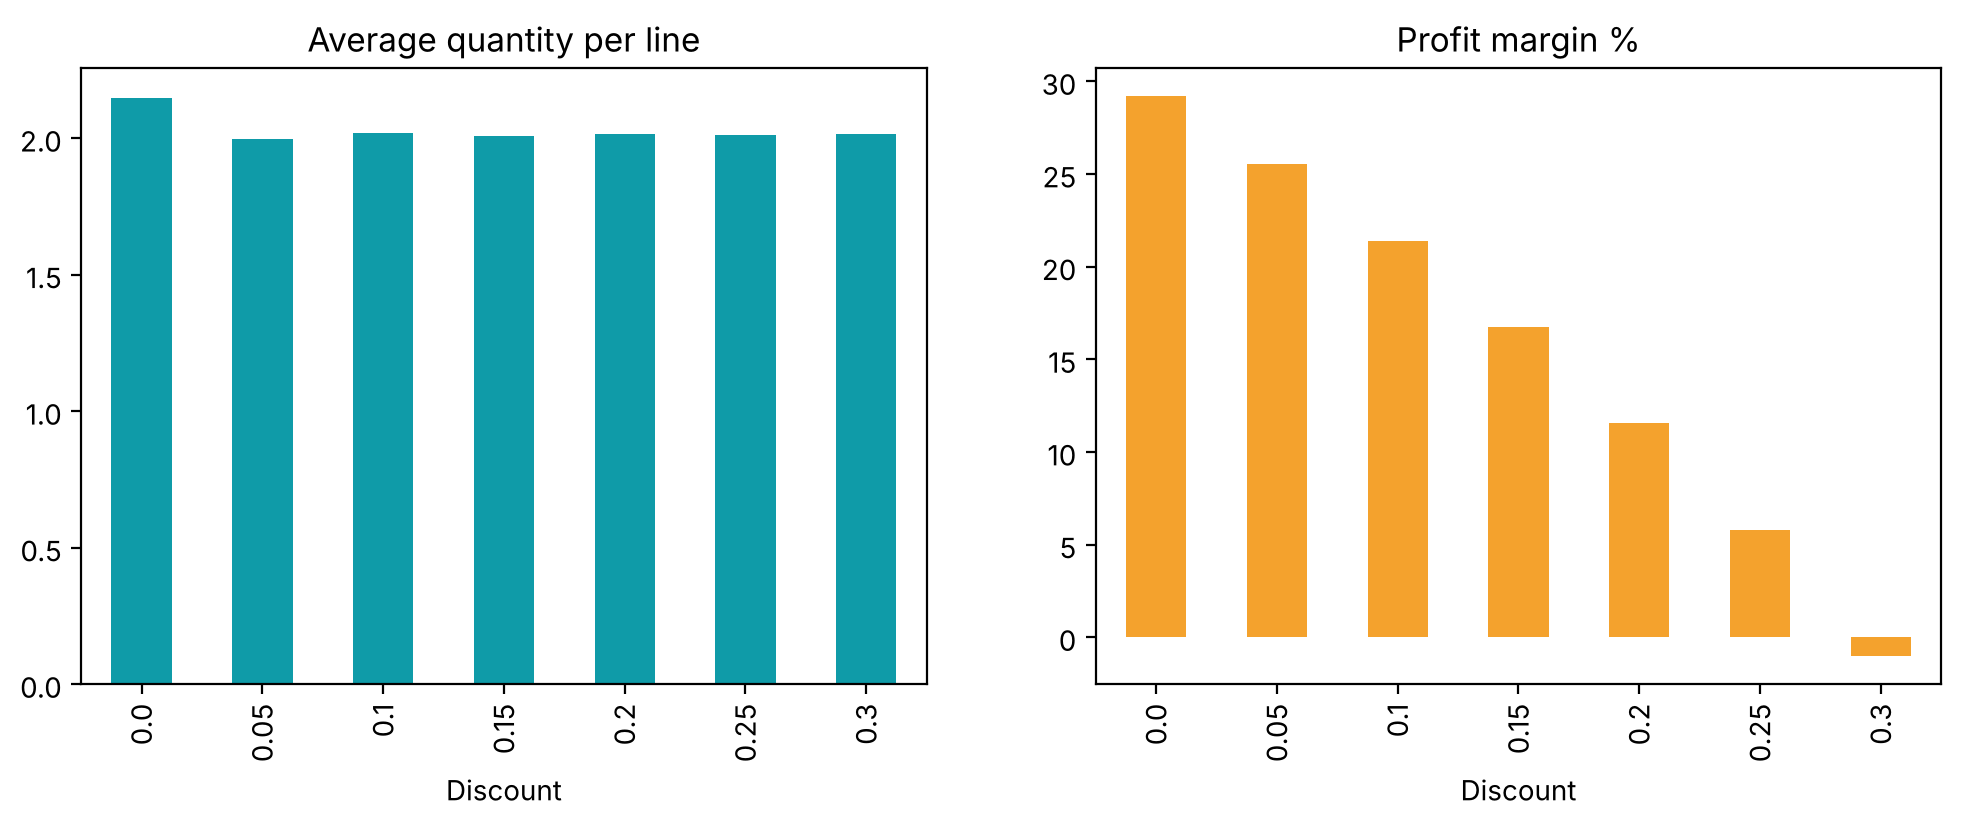

Insight: discounts do not increase the quantity sold, but they reduce the margin.
At 30% discount the margin is below zero.


In [8]:
levels = [0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
d = df[df["Discount"].isin(levels)]

by_discount = d.groupby("Discount").agg(
    Avg_Quantity=("Quantity", "mean"),
    Revenue=("Revenue", "sum"),
    Profit=("Profit", "sum"),
)
by_discount["Margin %"] = by_discount["Profit"] / by_discount["Revenue"] * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_discount["Avg_Quantity"].plot(kind="bar", color="#0F9BA8", ax=axes[0], title="Average quantity per line")
by_discount["Margin %"].plot(kind="bar", color="#F4A22D", ax=axes[1], title="Profit margin %")
plt.show()

print("Insight: discounts do not increase the quantity sold, but they reduce the margin.")
print("At 30% discount the margin is below zero.")

In [9]:
extra_profit = (df["Gross"] * (df["Discount"] - 0.15).clip(lower=0)).sum()
print("If discounts were limited to 15%, profit could increase by about", round(extra_profit / 1e6, 2), "M")
print("(only if the quantities stay the same)")

If discounts were limited to 15%, profit could increase by about 0.73 M
(only if the quantities stay the same)


## 4. Products sold below cost

In [10]:
products = df.groupby("Product").agg(
    Price=("Unit_Price", "mean"),
    Cost=("Cost_Price", "mean"),
    Profit=("Profit", "sum"),
)
below_cost = products[products["Cost"] > products["Price"]]
below_cost.round(2)

,Price,Cost,Profit
Product,,,
Cake Slice,26.40,30.0,-46307.02
Milk 500ml,19.01,21.6,-31315.97
Soda Can 330ml,12.68,14.4,-21727.59


In [11]:
print("Total loss from these products:", round(below_cost["Profit"].sum()), "EGP")
print("Their cost is higher than their price, so they should be checked.")

Total loss from these products: -99351 EGP
Their cost is higher than their price, so they should be checked.


## 5. Customers

In [12]:
customer_revenue = df.groupby("Customer_ID")["Revenue"].sum().sort_values(ascending=False)
top_20 = customer_revenue.head(int(len(customer_revenue) * 0.2)).sum() / customer_revenue.sum()

print("Top 20% of customers bring", round(top_20 * 100), "% of the revenue.")

Top 20% of customers bring 63 % of the revenue.


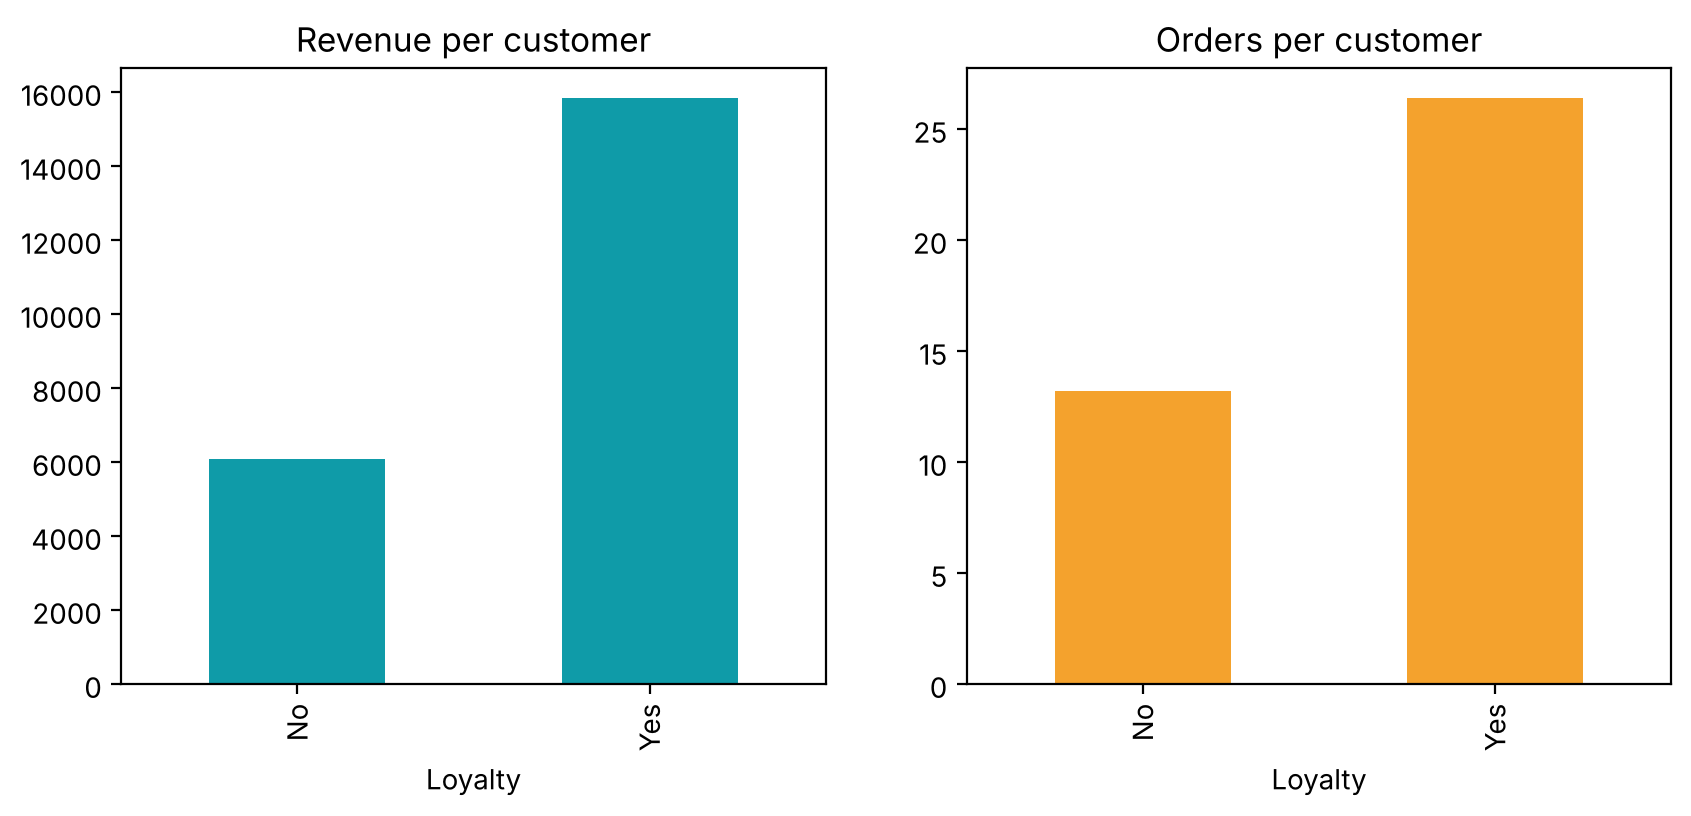

Insight: loyalty members spend and buy much more than non-members.


In [13]:
customers = df.groupby("Customer_ID").agg(
    Loyalty=("Loyalty_Member", "first"),
    Revenue=("Revenue", "sum"),
)
customers["Orders"] = invoices.groupby("Customer_ID").size()

loyalty = customers.groupby("Loyalty")[["Revenue", "Orders"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
loyalty["Revenue"].plot(kind="bar", color="#0F9BA8", ax=axes[0], title="Revenue per customer")
loyalty["Orders"].plot(kind="bar", color="#F4A22D", ax=axes[1], title="Orders per customer")
plt.show()

print("Insight: loyalty members spend and buy much more than non-members.")

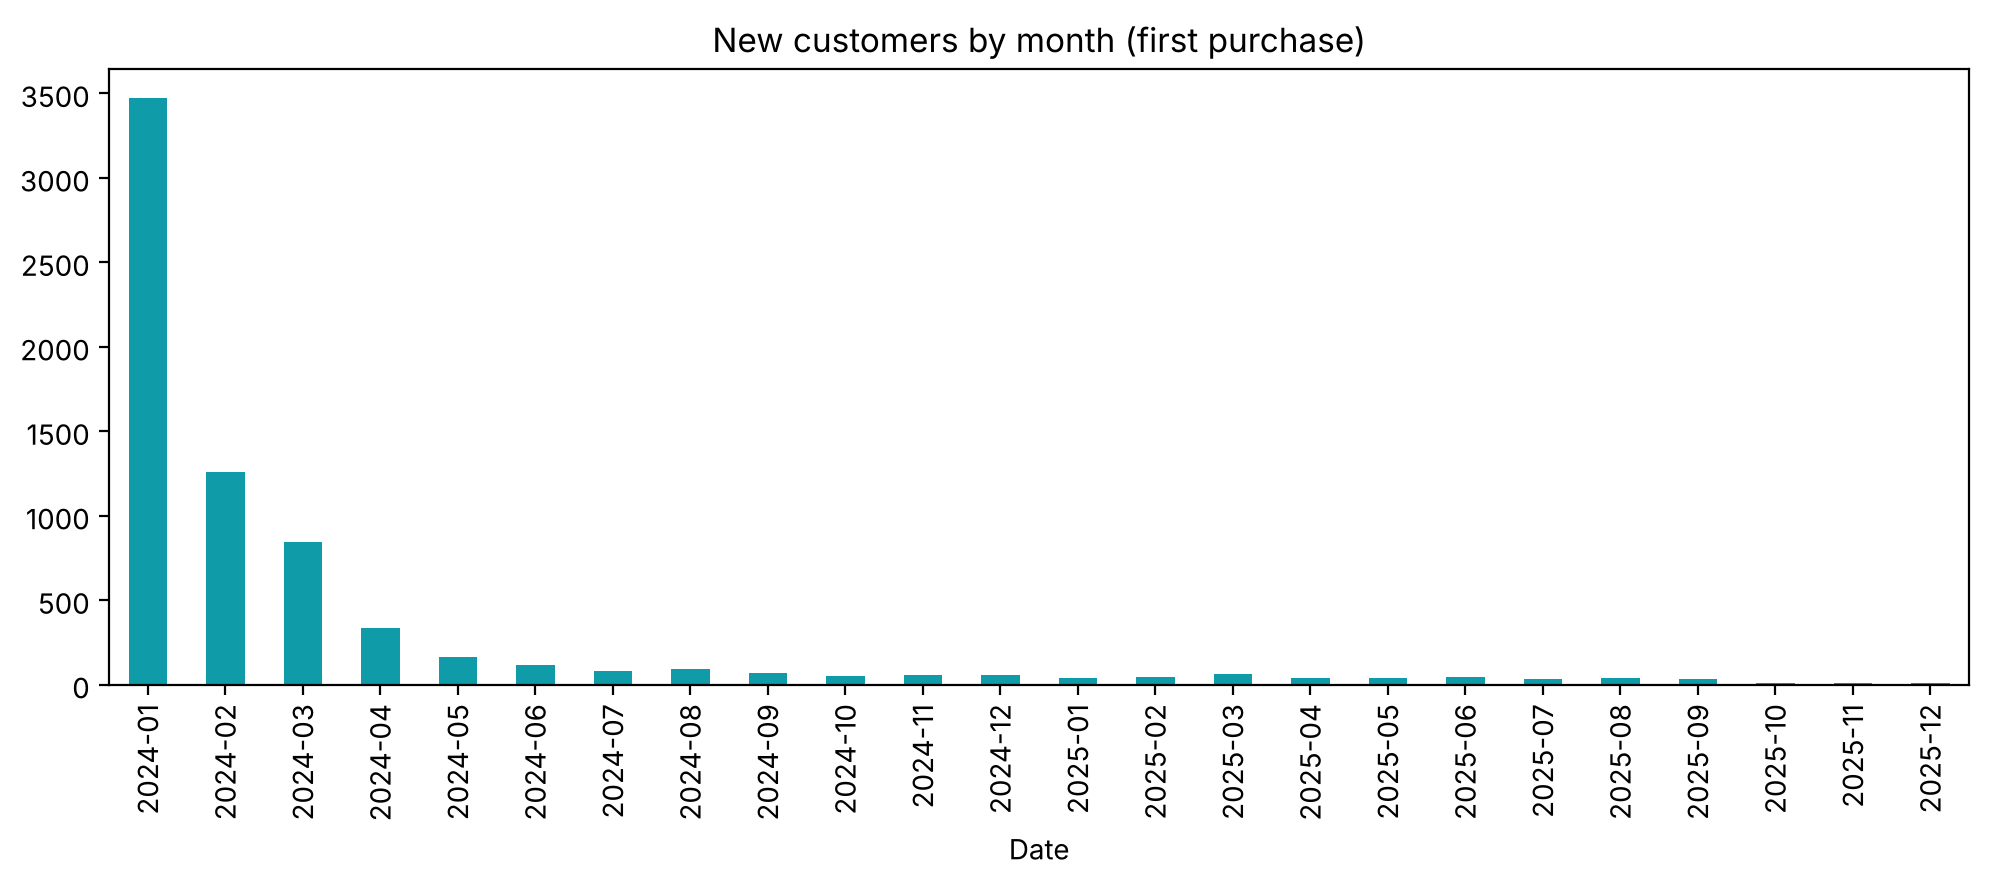

Insight: new customers per month went from about 80 in mid 2024 to about 10 at the end of 2025.


In [14]:
first_purchase = invoices.groupby("Customer_ID")["Date"].min().dt.to_period("M")
new_customers = first_purchase.value_counts().sort_index()

new_customers.plot(kind="bar", color="#0F9BA8", figsize=(12, 4))
plt.title("New customers by month (first purchase)")
plt.show()

print("Insight: new customers per month went from about",
      round(new_customers["2024-07":"2024-09"].mean()), "in mid 2024 to about",
      round(new_customers["2025-10":"2025-12"].mean()), "at the end of 2025.")

In [15]:
last_purchase = invoices.groupby("Customer_ID")["Date"].max()
days_since = (df["Date"].max() - last_purchase).dt.days
inactive = days_since[days_since > 90].index

print("Customers with no purchase in the last 90 days:", len(inactive))
print("Share of all customers:", round(len(inactive) / len(customers) * 100, 1), "%")
print("Their share of revenue:", round(customers.loc[inactive, "Revenue"].sum() / customers["Revenue"].sum() * 100, 1), "%")

Customers with no purchase in the last 90 days: 2060
Share of all customers: 29.4 %
Their share of revenue: 8.7 %


## 6. Channels and stores

In [16]:
channels = invoices.groupby("Channel").agg(
    Invoices=("Revenue", "size"),
    Avg_Invoice=("Revenue", "mean"),
    Revenue=("Revenue", "sum"),
    Profit=("Profit", "sum"),
)
channels["Margin %"] = channels["Profit"] / channels["Revenue"] * 100
channels.round(2)

,Invoices,Avg_Invoice,Revenue,Profit,Margin %
Channel,,,,,
Delivery,13777,548.94,7562718.74,2020647.33,26.72
In-Store,115873,551.11,63859102.22,17087857.94,26.76
Online Pickup,6787,548.22,3720762.84,993680.19,26.71


In [17]:
print("Insight: all channels have almost the same invoice value and margin.")

Insight: all channels have almost the same invoice value and margin.


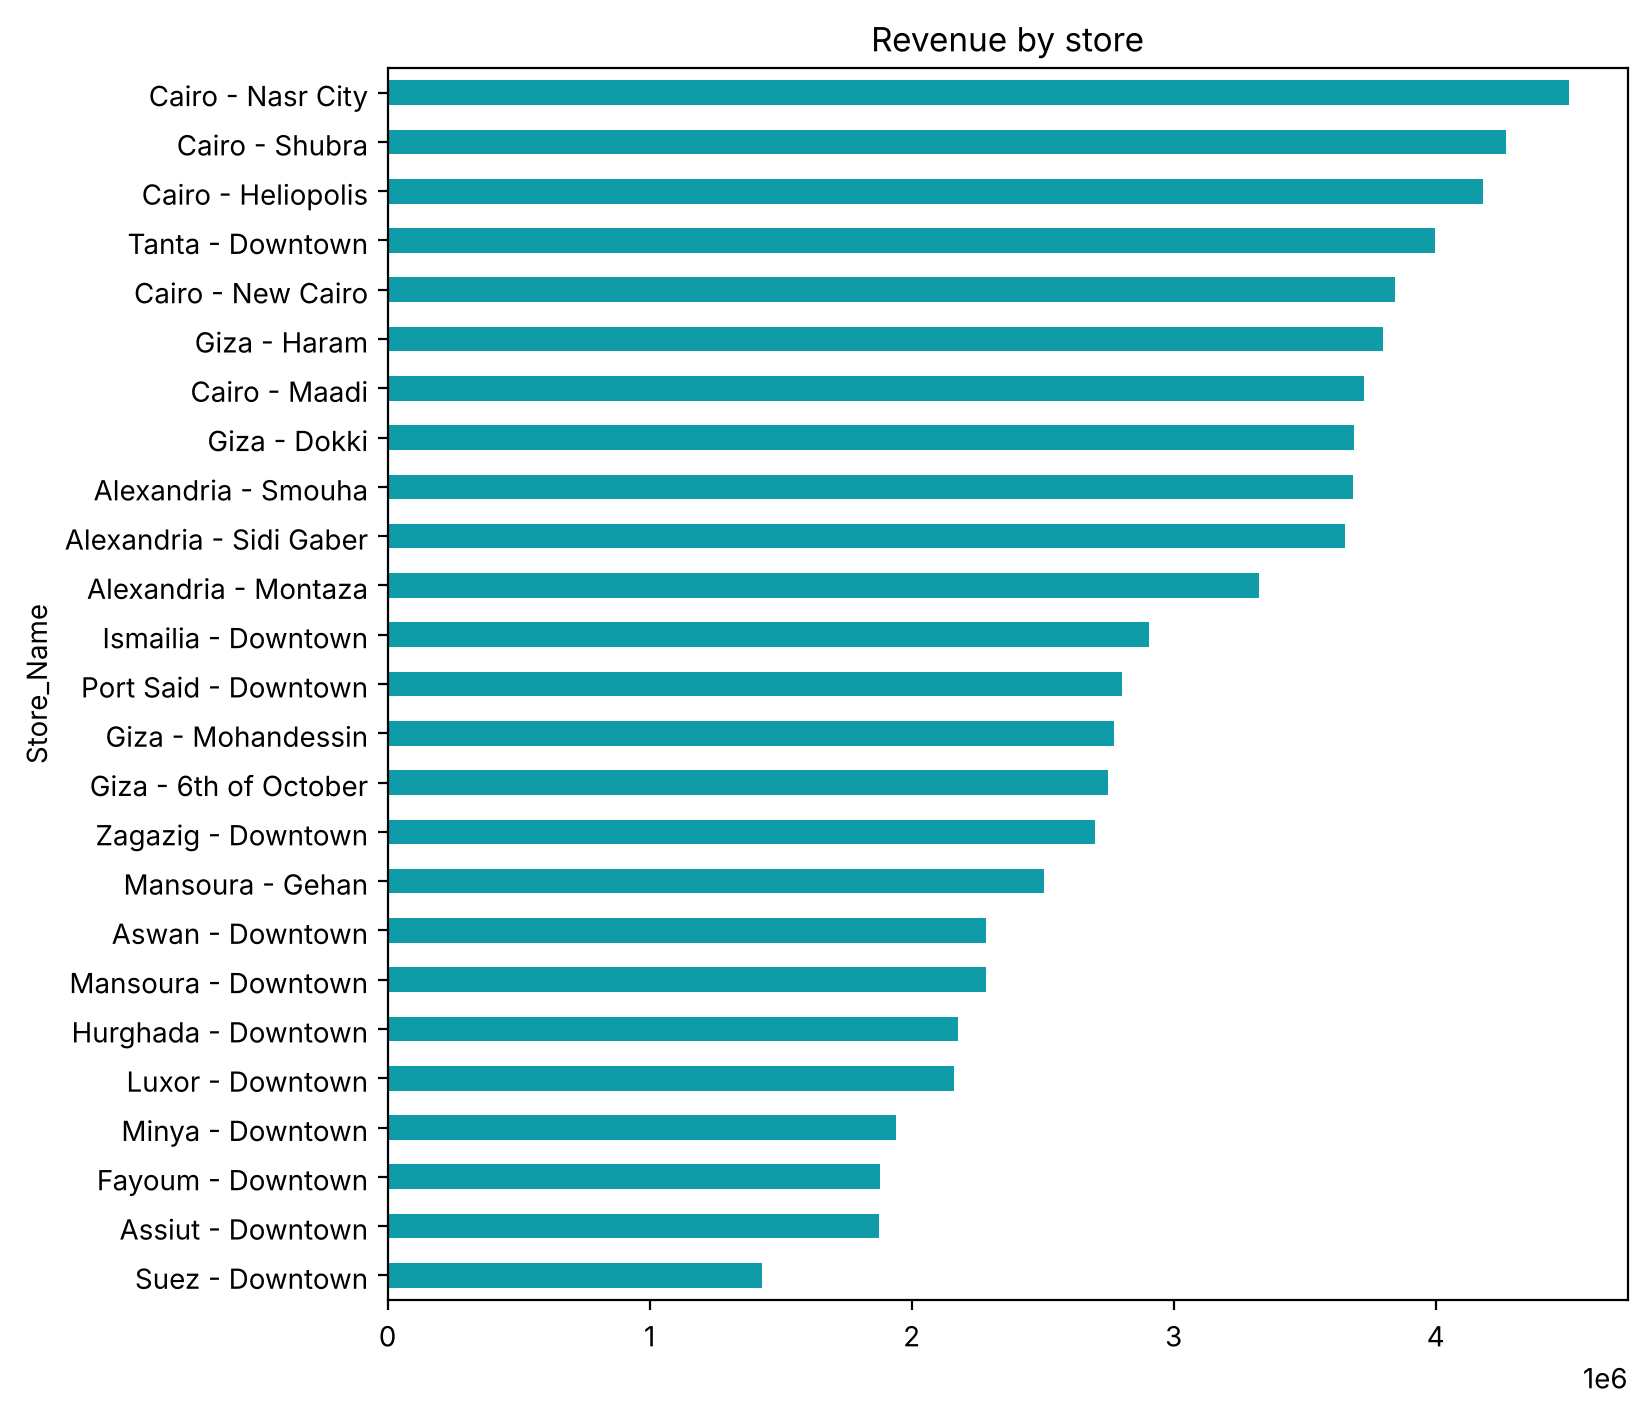

Margin range: 26.4 % to 27.0 %
Insight: all stores have the same margin, so the difference between stores is only in sales volume.


In [18]:
stores = df.groupby("Store_Name").agg(Revenue=("Revenue", "sum"), Profit=("Profit", "sum"))
stores = stores.drop("Unknown")
stores["Margin %"] = stores["Profit"] / stores["Revenue"] * 100

stores["Revenue"].sort_values().plot(kind="barh", color="#0F9BA8", figsize=(8, 8))
plt.title("Revenue by store")
plt.show()

print("Margin range:", round(stores["Margin %"].min(), 1), "% to", round(stores["Margin %"].max(), 1), "%")
print("Insight: all stores have the same margin, so the difference between stores is only in sales volume.")

## 7. Data quality

In [19]:
before_join = (pd.to_datetime(df["Join_Date"]) > df["Date"]).mean()
print("Lines with a date before the customer join date:", round(before_join * 100, 1), "%")
print("Lines sold at a loss:", round((df["Profit"] < 0).mean() * 100, 1), "%")
print("Duplicate rows:", df.duplicated().sum())
print("Stores in the data:", df["Store_Name"].nunique())
print("Lines with store name Unknown:", (df["Store_Name"] == "Unknown").sum())
print("The dashboard shows 26 stores, but one is Unknown, so the real number is", df["Store_Name"].nunique() - 1)

Lines with a date before the customer join date: 9.4 %
Lines sold at a loss: 3.2 %


Duplicate rows: 0
Stores in the data: 26
Lines with store name Unknown: 2
The dashboard shows 26 stores, but one is Unknown, so the real number is 25


## 8. Customer segments (RFM + KMeans)

Recency, Frequency and Monetary in `data.csv` are log values, so they are converted back to real numbers first.

In [1001]:
seg = df.groupby("Customer_ID").agg(
    Segment=("Segment", "first"),
    Recency=("Recency", "first"),
    Frequency=("Frequency", "first"),
    Monetary=("Monetary", "first"),
    Loyalty=("Loyalty_Member", "first"),
    Gender=("Gender", "first"),
    Age=("Age_Group", "first"),
    Payment=("Preferred_Payment", "first"),
    Gross=("Gross", "sum"),
    Spend=("Revenue", "sum"),
    Profit=("Profit", "sum"),
)
seg[["Recency", "Frequency", "Monetary"]] = np.expm1(seg[["Recency", "Frequency", "Monetary"]])
invoices["Segment"] = invoices["Customer_ID"].map(seg["Segment"])

profile = seg.groupby("Segment").agg(
    Customers=("Spend", "size"),
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"),
).round(1).sort_values("Monetary", ascending=False)

order = profile.index.tolist()
profile

,Customers,Recency,Frequency,Monetary
Segment,,,,
Champions,764,10.7,56.6,13670.9
Loyal Customers,1335,40.9,25.4,5126.2
Valuable Customers,1049,7.0,25.5,5102.7
Potential Loyal Customers,979,55.0,11.0,1915.6
At Risk Customers,1026,441.4,10.4,1748.9
Recent High Spenders,700,11.6,8.3,1299.4
Hibernating Customers,864,179.3,5.6,851.0
Lost Customers,283,319.3,2.0,271.6


In [1002]:
print("Recency = days since last purchase, Frequency = number of invoices")
print("Insight: Champions are only", profile.loc["Champions", "Customers"], "customers, but each one has about",
      round(profile.loc["Champions", "Frequency"]), "invoices and bought about",
      round(profile.loc["Champions", "Recency"]), "days ago.")
print("Insight: At Risk customers last bought about", round(profile.loc["At Risk Customers", "Recency"]),
      "days ago, and Lost customers have only", round(profile.loc["Lost Customers", "Frequency"]), "invoices on average.")

Recency = days since last purchase, Frequency = number of invoices
Insight: Champions are only 764 customers, but each one has about 57 invoices and bought about 11 days ago.
Insight: At Risk customers last bought about 441 days ago, and Lost customers have only 2 invoices on average.


### Who are the customers

In [1003]:
for col in ["Loyalty", "Gender", "Age", "Payment"]:
    table = pd.crosstab(seg["Segment"], seg[col], normalize="index") * 100
    print(col, "- % inside each segment")
    display(table.loc[order].round(1))

Loyalty - % inside each segment
Gender - % inside each segment
Age - % inside each segment
Payment - % inside each segment


Loyalty,No,Yes
Segment,,
Champions,17.7,82.3
Loyal Customers,29.8,70.2
Valuable Customers,32.0,68.0
Potential Loyal Customers,67.9,32.1
At Risk Customers,72.4,27.6
Recent High Spenders,74.1,25.9
Hibernating Customers,75.3,24.7
Lost Customers,78.4,21.6


Gender,Female,Male,Unknown
Segment,,,
Champions,51.2,47.3,1.6
Loyal Customers,54.8,44.0,1.2
Valuable Customers,50.1,49.2,0.7
Potential Loyal Customers,52.4,46.1,1.5
At Risk Customers,54.4,44.6,1.0
Recent High Spenders,52.4,47.0,0.6
Hibernating Customers,50.7,47.5,1.9
Lost Customers,58.0,41.0,1.1


Age,18-24,25-34,35-44,45-54,55+
Segment,,,,,
Champions,9.9,31.9,30.2,17.8,10.1
Loyal Customers,13.0,29.8,28.8,16.6,11.8
Valuable Customers,13.2,31.3,26.2,17.5,11.8
Potential Loyal Customers,11.4,33.0,27.3,17.1,11.2
At Risk Customers,12.6,30.0,27.1,19.3,11.0
Recent High Spenders,12.6,32.0,28.1,17.0,10.3
Hibernating Customers,12.5,32.2,25.9,16.7,12.7
Lost Customers,10.2,25.8,33.9,20.8,9.2


Payment,Cash,Credit Card,Mobile Wallet
Segment,,,
Champions,57.3,27.0,15.7
Loyal Customers,55.1,30.6,14.3
Valuable Customers,53.8,32.8,13.4
Potential Loyal Customers,55.9,29.5,14.6
At Risk Customers,54.2,29.1,16.7
Recent High Spenders,53.9,30.4,15.7
Hibernating Customers,55.7,30.1,14.2
Lost Customers,51.9,32.5,15.5


In [1004]:
print("Insight: loyalty is the only thing that separates the segments.")
print("82% of Champions are loyalty members, against 22% of Lost customers.")
print("Gender, age and payment method are almost the same in all segments.")

Insight: loyalty is the only thing that separates the segments.
82% of Champions are loyalty members, against 22% of Lost customers.
Gender, age and payment method are almost the same in all segments.


### What they buy

Insight: Eggs & Poultry and Dairy are the biggest categories in every segment.
Champions spend relatively more on Personal Care and Fruits & Vegetables, and less on Baby & Kids.


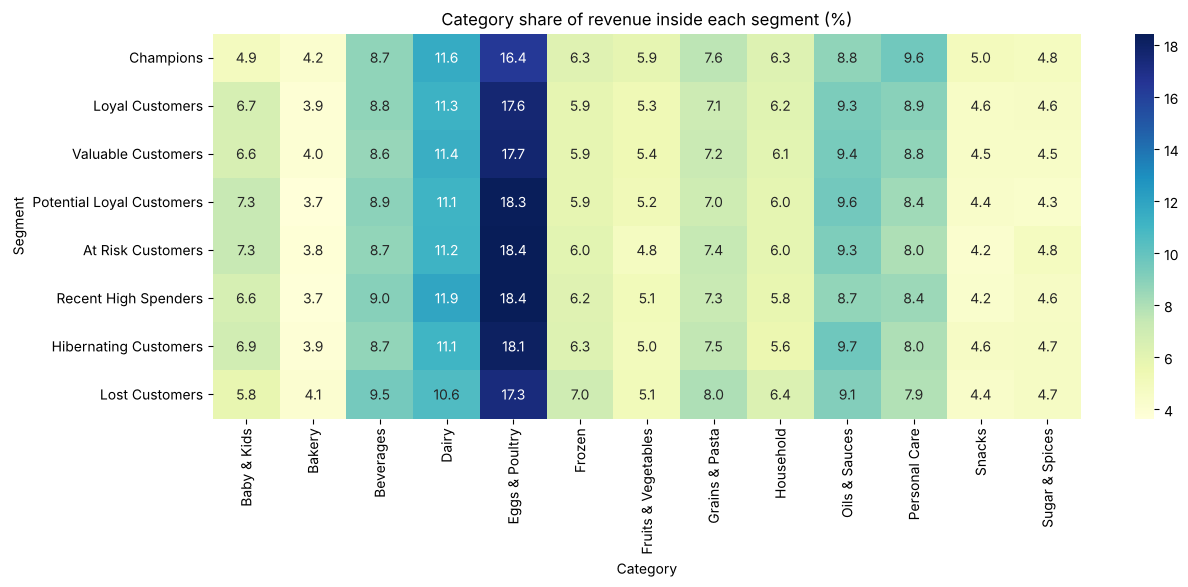

In [1005]:
cat = df.pivot_table(index="Segment", columns="Category", values="Revenue", aggfunc="sum")
cat = cat.div(cat.sum(axis=1), axis=0).loc[order] * 100

plt.figure(figsize=(14, 5))
sns.heatmap(cat, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Category share of revenue inside each segment (%)")
plt.show()

print("Insight: Eggs & Poultry and Dairy are the biggest categories in every segment.")
print("Champions spend relatively more on Personal Care and Fruits & Vegetables, and less on Baby & Kids.")

Insight: Loyal and Valuable customers get the highest discount (about 4.6%), more than Champions (2.7%).
At Risk, Hibernating and Lost customers get only about 1.5%.


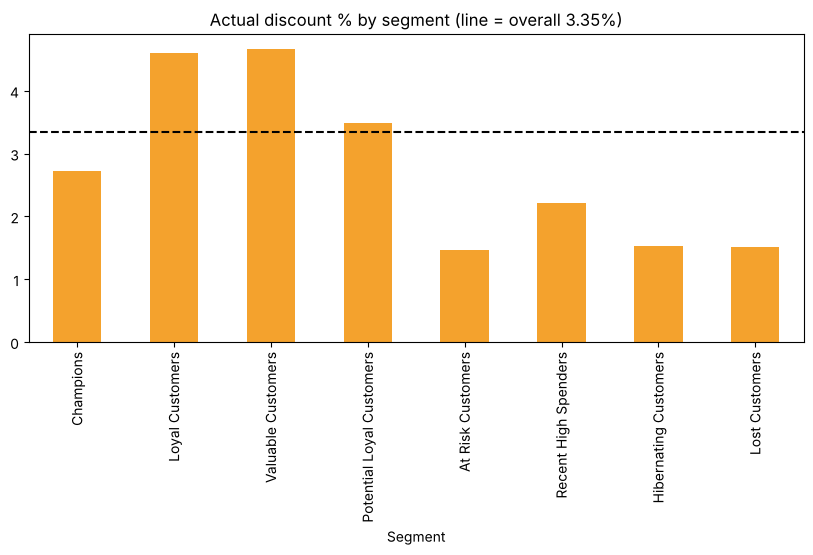

In [1006]:
disc = df.groupby("Segment")[["Gross", "Revenue"]].sum()
disc["Discount %"] = (1 - disc["Revenue"] / disc["Gross"]) * 100
disc = disc.loc[order]
overall = (1 - df["Revenue"].sum() / df["Gross"].sum()) * 100

disc["Discount %"].plot(kind="bar", color="#F4A22D", figsize=(10, 4))
plt.axhline(overall, color="black", linestyle="--")
plt.title("Actual discount % by segment (line = overall " + str(round(overall, 2)) + "%)")
plt.show()

print("Insight: Loyal and Valuable customers get the highest discount (about 4.6%), more than Champions (2.7%).")
print("At Risk, Hibernating and Lost customers get only about 1.5%.")

### Revenue and profit by segment

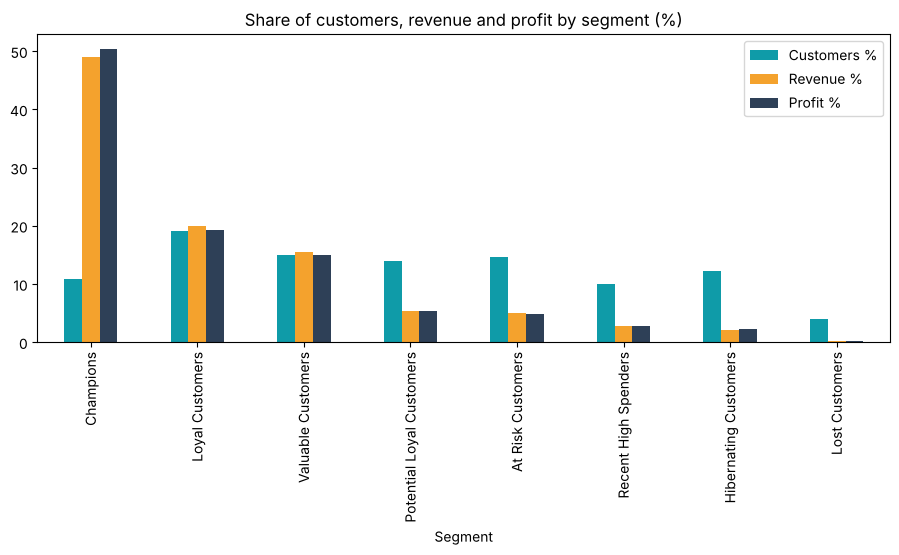

,Customers %,Revenue %,Profit %
Segment,,,
Champions,10.9,49.0,50.4
Loyal Customers,19.1,20.0,19.2
Valuable Customers,15.0,15.5,14.9
Potential Loyal Customers,14.0,5.4,5.4
At Risk Customers,14.7,5.0,4.8
Recent High Spenders,10.0,2.7,2.8
Hibernating Customers,12.3,2.1,2.2
Lost Customers,4.0,0.2,0.2


In [1007]:
share = pd.DataFrame({
    "Customers %": seg.groupby("Segment").size() / len(seg) * 100,
    "Revenue %": seg.groupby("Segment")["Spend"].sum() / seg["Spend"].sum() * 100,
    "Profit %": seg.groupby("Segment")["Profit"].sum() / seg["Profit"].sum() * 100,
}).loc[order].round(1)

share.plot(kind="bar", color=["#0F9BA8", "#F4A22D", "#2E4057"], figsize=(11, 4))
plt.title("Share of customers, revenue and profit by segment (%)")
plt.show()
share

In [1008]:
weak = ["Potential Loyal Customers", "At Risk Customers", "Recent High Spenders", "Hibernating Customers", "Lost Customers"]
print("Insight: Champions are", share.loc["Champions", "Customers %"], "% of customers but bring",
      share.loc["Champions", "Revenue %"], "% of revenue and", share.loc["Champions", "Profit %"], "% of profit.")
print("Insight: the 5 weakest segments are", round(share.loc[weak, "Customers %"].sum(), 1),
      "% of customers but only", round(share.loc[weak, "Revenue %"].sum(), 1), "% of revenue.")

Insight: Champions are 10.9 % of customers but bring 49.0 % of revenue and 50.4 % of profit.
Insight: the 5 weakest segments are 55.0 % of customers but only 15.4 % of revenue.


### All segments in one view

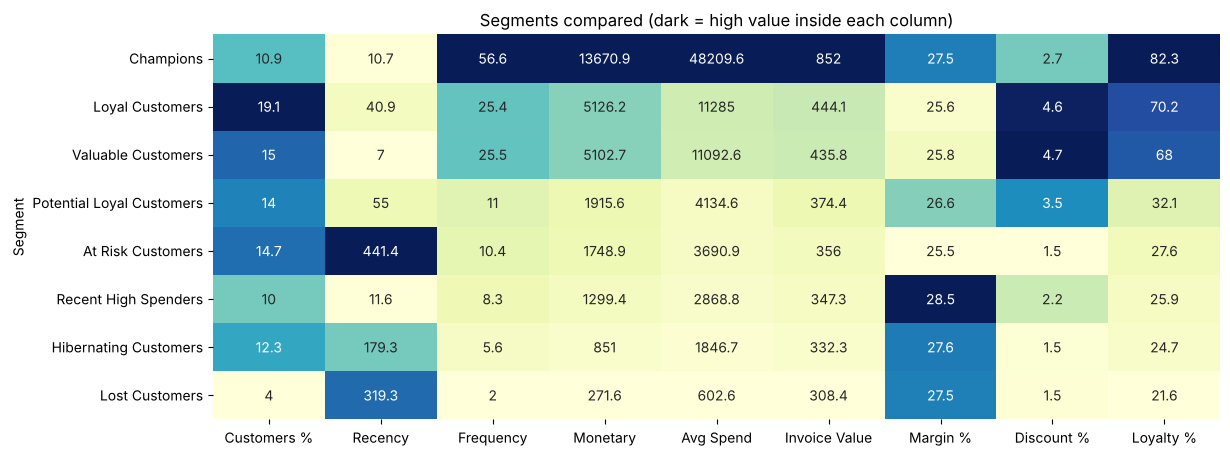

In [1009]:
summary = pd.DataFrame({
    "Customers %": share["Customers %"],
    "Recency": profile["Recency"],
    "Frequency": profile["Frequency"],
    "Monetary": profile["Monetary"],
    "Avg Spend": seg.groupby("Segment")["Spend"].mean(),
    "Invoice Value": invoices.groupby("Segment")["Revenue"].mean(),
    "Margin %": seg.groupby("Segment")["Profit"].sum() / seg.groupby("Segment")["Spend"].sum() * 100,
    "Discount %": disc["Discount %"],
    "Loyalty %": (seg["Loyalty"] == "Yes").groupby(seg["Segment"]).mean() * 100,
}).loc[order]

scaled = (summary - summary.min()) / (summary.max() - summary.min())

plt.figure(figsize=(13, 5))
sns.heatmap(scaled, annot=summary.round(1), fmt="g", cmap="YlGnBu", cbar=False)
plt.title("Segments compared (dark = high value inside each column)")
plt.show()

In [1010]:
print("Note: for Recency, dark means the customer bought a long time ago.")
print("Insight: Champions lead every volume measure, and their invoice is about 850 against 300 to 450 for the others.")
print("Insight: margin is similar in all segments (25% to 29%), but Loyal and Valuable are at 25.6% and 25.8% against 27.5% for Champions, and they get the highest discount.")

Note: for Recency, dark means the customer bought a long time ago.
Insight: Champions lead every volume measure, and their invoice is about 850 against 300 to 450 for the others.
Insight: margin is similar in all segments (25% to 29%), but Loyal and Valuable are at 25.6% and 25.8% against 27.5% for Champions, and they get the highest discount.


### Are the segment names right?

In [1011]:
names = profile[["Recency", "Frequency", "Monetary"]].copy()
names["Recency Rank"] = names["Recency"].rank().astype(int)
names["Frequency Rank"] = names["Frequency"].rank(ascending=False).astype(int)
names["Monetary Rank"] = names["Monetary"].rank(ascending=False).astype(int)
names

,Recency,Frequency,Monetary,Recency Rank,Frequency Rank,Monetary Rank
Segment,,,,,,
Champions,10.7,56.6,13670.9,2,1,1
Loyal Customers,40.9,25.4,5126.2,4,3,2
Valuable Customers,7.0,25.5,5102.7,1,2,3
Potential Loyal Customers,55.0,11.0,1915.6,5,4,4
At Risk Customers,441.4,10.4,1748.9,8,5,5
Recent High Spenders,11.6,8.3,1299.4,3,6,6
Hibernating Customers,179.3,5.6,851.0,6,7,7
Lost Customers,319.3,2.0,271.6,7,8,8


In [1012]:
print("Fits the numbers: Champions, Potential Loyal, Hibernating and Lost.")
print("Recent High Spenders: only 6th of 8 in Monetary, so they are not high spenders. They are new or recent customers.")
print("At Risk Customers: last purchase was about 441 days ago, the oldest of all segments, so they are already gone.")
print("Loyal and Valuable: same Frequency and Monetary, the only difference is Recency (41 days vs 7 days).")

suggested = pd.DataFrame({
    "Current Name": ["Recent High Spenders", "At Risk Customers", "Valuable Customers"],
    "Suggested Name": ["New Customers", "Churned Customers", "Active Loyal Customers"],
})
suggested

Fits the numbers: Champions, Potential Loyal, Hibernating and Lost.
Recent High Spenders: only 6th of 8 in Monetary, so they are not high spenders. They are new or recent customers.
At Risk Customers: last purchase was about 441 days ago, the oldest of all segments, so they are already gone.
Loyal and Valuable: same Frequency and Monetary, the only difference is Recency (41 days vs 7 days).


,Current Name,Suggested Name
0,Recent High Spenders,New Customers
1,At Risk Customers,Churned Customers
2,Valuable Customers,Active Loyal Customers


### Monetary vs real spending

In [1013]:
compare = seg.groupby("Segment")[["Monetary", "Spend"]].mean().loc[order].round(0)
compare["Spend / Monetary"] = (compare["Spend"] / compare["Monetary"]).round(2)

print("Total real spend is", round(seg["Spend"].sum() / seg["Monetary"].sum(), 2), "times the total Monetary.")
print("Correlation between Monetary and real spend:", round(seg["Monetary"].corr(seg["Spend"]), 3))
compare

Total real spend is 2.68 times the total Monetary.
Correlation between Monetary and real spend: 0.975


,Monetary,Spend,Spend / Monetary
Segment,,,
Champions,13671.0,48210.0,3.53
Loyal Customers,5126.0,11285.0,2.20
Valuable Customers,5103.0,11093.0,2.17
Potential Loyal Customers,1916.0,4135.0,2.16
At Risk Customers,1749.0,3691.0,2.11
Recent High Spenders,1299.0,2869.0,2.21
Hibernating Customers,851.0,1847.0,2.17
Lost Customers,272.0,603.0,2.22


In [1014]:
print("Insight: Monetary is the sum of Cost_Price per line, so it ignores Quantity and the selling price.")
print("Insight: it is about 2.2 times smaller than real spend in most segments, but 3.5 times smaller for Champions,")
print("because Champions buy about 2.85 units per line against about 1.65 for the others.")
print("Insight: the segment ranking is the same with both measures, so the segments are still valid.")
print("Better Monetary: Revenue = Quantity x Unit_Price x (1 - Discount).")

Insight: Monetary is the sum of Cost_Price per line, so it ignores Quantity and the selling price.
Insight: it is about 2.2 times smaller than real spend in most segments, but 3.5 times smaller for Champions,
because Champions buy about 2.85 units per line against about 1.65 for the others.
Insight: the segment ranking is the same with both measures, so the segments are still valid.
Better Monetary: Revenue = Quantity x Unit_Price x (1 - Discount).
